# 16 — Original MONAI 3D U-Net: brain, skull, and joint brain+skull

This is a **task ablation using the original project's MONAI U-Net architecture**, not its old
10-organ checkpoint. Three new models are trained from scratch:

1. **brain-only:** background vs brain;
2. **skull-only:** background vs skull;
3. **joint:** background vs brain vs skull.

All three use the same 98 training / 5 validation complete-head cases from Notebook 15, one fixed
`[-1000, 1000] HU → [0, 1]` CT channel, **identical sampled `96³` patch centers**, Dice+CE loss,
AdamW, and 50 epochs. The network
matches the original model's five feature levels `[16, 32, 64, 128, 256]`, four stride-2 downsamples,
two residual units per level, instance normalization, and PReLU; only the output channels change.

This is a controlled comparison of **task formulation**, not an exact rerun of the original 10-organ
training recipe: the head-case selection and augmentation are benchmark-specific. The official test
split remains unopened. Development crops use reference masks, so the scores are not deployable
CT-only or independent clinical performance estimates.

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import monai
from IPython.display import Markdown, display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    raise RuntimeError("Run from the F:/csstdy project root")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.benchmark.brain_skull import (
    ORIGINAL_INPUT_CHANNEL,
    ORIGINAL_TASKS,
    load_or_create_inventory,
    make_model,
    predict_case,
    prepare_inventory,
    prepare_original_inputs,
    sha256_file,
    train_model,
)

DATASET_ROOT = Path(
    os.environ.get("TOTALSEG_DATASET_ROOT", PROJECT_ROOT / "Totalsegmentator_dataset_v201")
).resolve()
MANIFEST_PATH = PROJECT_ROOT / "data" / "splits" / "dataset_manifest.json"
INVENTORY_PATH = PROJECT_ROOT / "outputs" / "brain_skull_benchmark" / "development_inventory.json"
CACHE_ROOT = PROJECT_ROOT / "data" / "cache" / "brain_skull_benchmark"
OUTPUT_ROOT = PROJECT_ROOT / "outputs" / "original_monai_head_ablation_matched"

MODEL_NAMES = tuple(ORIGINAL_TASKS)
MAX_EPOCHS = 50
ROI = 96
LEARNING_RATE = 1e-4
SEED = 42

if not torch.cuda.is_available():
    raise RuntimeError("CUDA is required; refusing silent CPU fallback")
print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch / MONAI:", torch.__version__, "/", monai.__version__)
print("Original input channel:", ORIGINAL_INPUT_CHANNEL)
print("Models:", MODEL_NAMES)

F:\csstdy\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


F:\csstdy\.venv\Lib\site-packages\torch\jit\_script.py:1643: FutureWarning: `torch.jit.interface` is deprecated. Please use `torch.compile` instead.
  warnings.warn(


GPU: NVIDIA GeForce RTX 4060 Laptop GPU
PyTorch / MONAI: 2.14.0+cu130 / 1.6.0
Original input channel: original_window_-1000_1000_HU
Models: ('original_monai_brain_only', 'original_monai_skull_only', 'original_monai_brain_skull')


## 1. Reuse the frozen development cohort and make the original CT channel

The same exclusive target map is used in all three tasks: skull wins voxels where the two source masks
overlap. The brain-only and skull-only labels are derived from that map. At each epoch, all three runs
see the same case order, the same brain/skull-centered patch locations, and the same spatial flips;
only the target channels differ. The prior two-window benchmark cache is not modified.

In [2]:
inventory = load_or_create_inventory(DATASET_ROOT, MANIFEST_PATH, INVENTORY_PATH)
assert inventory["test_split_accessed"] is False
assert inventory["selected_counts"] == {"train": 98, "val": 5}
prepared = prepare_inventory(DATASET_ROOT, inventory, CACHE_ROOT)
prepared = prepare_original_inputs(DATASET_ROOT, prepared, CACHE_ROOT)
assert all(item["split"] in {"train", "val"} for item in prepared)
val_records = [item for item in prepared if item["split"] == "val"]
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
print("Prepared original one-channel CT input for", len(prepared), "cases")
print("Validation cases:", [item["case_id"] for item in val_records])

Prepared original one-channel CT input for 103 cases
Validation cases: ['s0346', 's0792', 's0874', 's1161', 's1260']


## 2. Train and save the three original-architecture U-Nets

Every task has a distinct checkpoint contract and directory. `last.pt` resumes exact task training;
`best.pt` is selected by validation Dice for its target(s). Increasing `MAX_EPOCHS` continues the runs.

In [3]:
inventory_sha256 = sha256_file(INVENTORY_PATH)
reports = {}
for model_name in MODEL_NAMES:
    print(f"\n=== {model_name} ===", flush=True)
    reports[model_name] = train_model(
        model_name,
        prepared,
        OUTPUT_ROOT,
        inventory_sha256=inventory_sha256,
        max_epochs=MAX_EPOCHS,
        roi=ROI,
        learning_rate=LEARNING_RATE,
        seed=SEED,
    )
    assert reports[model_name]["test_split_accessed"] is False
    print("Best checkpoint:", reports[model_name]["best_checkpoint"])


=== original_monai_brain_only ===


Best checkpoint: F:\csstdy\outputs\original_monai_head_ablation_matched\original_monai_brain_only\best.pt

=== original_monai_skull_only ===


Best checkpoint: F:\csstdy\outputs\original_monai_head_ablation_matched\original_monai_skull_only\best.pt

=== original_monai_brain_skull ===


Best checkpoint: F:\csstdy\outputs\original_monai_head_ablation_matched\original_monai_brain_skull\best.pt


## 3. Compare separate versus joint training

The meaningful comparisons are **brain-only vs joint-brain** and **skull-only vs joint-skull** on the
same five validation scans. Dice measures volume overlap; HD95 measures boundary error in millimetres.
A brain-only Dice and skull-only Dice should not be averaged into a single model score, because they
come from separate checkpoints. A large HD95 despite strong Dice may indicate distant false-positive
components, so inspect the per-case table and overlays before using a mask for 3D reconstruction.

,Model,Task,Best epoch,Brain Dice,Skull Dice,Brain HD95 (mm),Skull HD95 (mm),Parameters,Training time (min)
0,original_monai_brain_only,brain_only,45,0.9602,—,69.4898,—,4806481,3.1663
1,original_monai_skull_only,skull_only,49,—,0.9526,—,2.0196,4806481,3.1986
2,original_monai_brain_skull,joint,28,0.9481,0.9243,71.0283,11.3387,4807482,3.4071


Joint minus brain-only Dice: -0.0121
Joint minus skull-only Dice: -0.0283


,case_id,brain_only_dice,joint_brain_dice,brain_joint_minus_single,brain_only_hd95_mm,joint_brain_hd95_mm,skull_only_dice,joint_skull_dice,skull_joint_minus_single,skull_only_hd95_mm,joint_skull_hd95_mm
0,s0346,0.9035,0.8925,-0.0110,129.1133,128.6677,0.9327,0.8916,-0.0411,3.0000,42.6907
1,s0792,0.9860,0.9820,-0.0039,1.5000,2.5981,0.9647,0.9569,-0.0078,1.5000,1.5000
2,s0874,0.9664,0.9292,-0.0372,109.5411,116.2960,0.9608,0.9216,-0.0392,1.5000,3.3541
3,s1161,0.9607,0.9491,-0.0117,105.7947,106.0798,0.9382,0.9013,-0.0369,2.5981,7.6485
4,s1260,0.9844,0.9877,0.0033,1.5000,1.5000,0.9665,0.9500,-0.0164,1.5000,1.5000


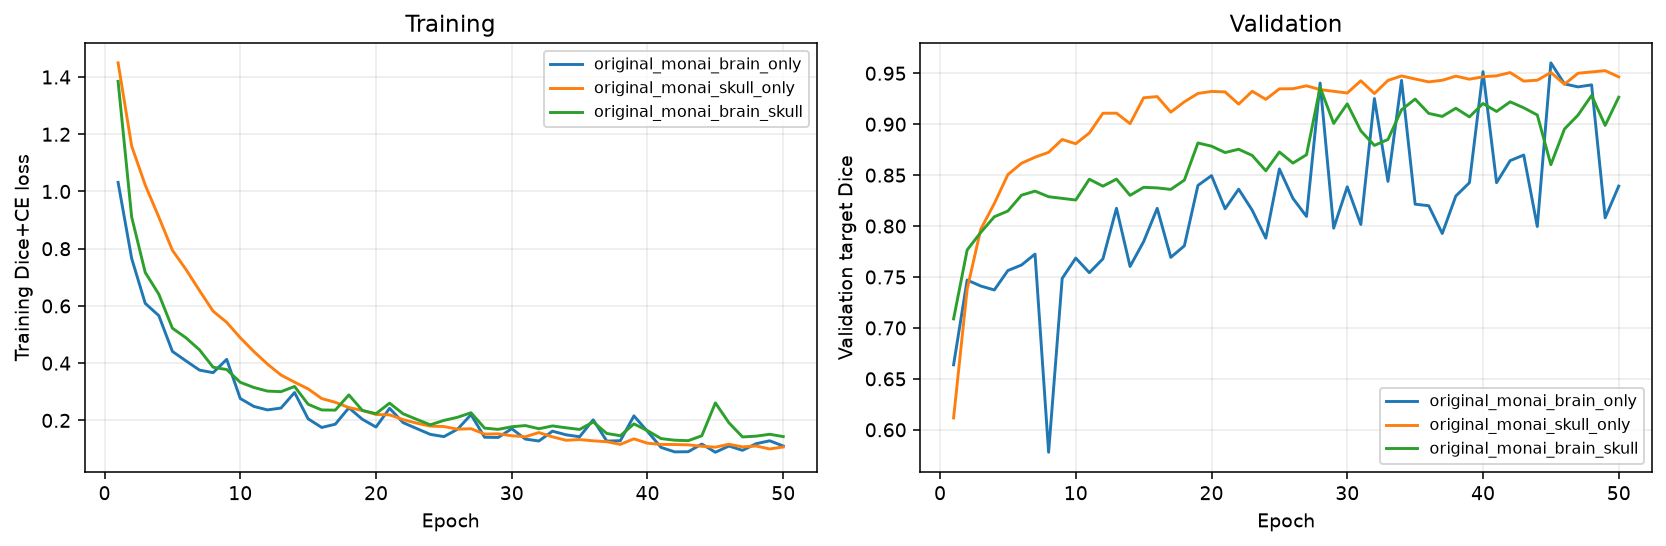

In [4]:
rows = []
for model_name, report in reports.items():
    validation = report["validation"]
    rows.append({
        "Model": model_name,
        "Task": report["task"],
        "Best epoch": report["selected_epoch"],
        "Brain Dice": validation["mean_dice"].get("brain"),
        "Skull Dice": validation["mean_dice"].get("skull"),
        "Brain HD95 (mm)": validation["mean_hd95_mm"].get("brain"),
        "Skull HD95 (mm)": validation["mean_hd95_mm"].get("skull"),
        "Parameters": report["parameter_count"],
        "Training time (min)": report["total_epoch_seconds"] / 60.0,
    })
comparison = pd.DataFrame(rows)
comparison.to_csv(OUTPUT_ROOT / "comparison_original_unet.csv", index=False)
display(comparison.style.format(precision=4, na_rep="—"))

brain_single = reports["original_monai_brain_only"]["validation"]["mean_dice"]["brain"]
skull_single = reports["original_monai_skull_only"]["validation"]["mean_dice"]["skull"]
joint = reports["original_monai_brain_skull"]["validation"]["mean_dice"]
print("Joint minus brain-only Dice:", round(joint["brain"] - brain_single, 4))
print("Joint minus skull-only Dice:", round(joint["skull"] - skull_single, 4))

by_case = {
    name: {item["case_id"]: item for item in report["validation"]["cases"]}
    for name, report in reports.items()
}
paired_rows = []
for case_id in sorted(by_case["original_monai_brain_skull"]):
    brain_separate = by_case["original_monai_brain_only"][case_id]
    skull_separate = by_case["original_monai_skull_only"][case_id]
    joint_case = by_case["original_monai_brain_skull"][case_id]
    paired_rows.append({
        "case_id": case_id,
        "brain_only_dice": brain_separate["dice"]["brain"],
        "joint_brain_dice": joint_case["dice"]["brain"],
        "brain_joint_minus_single": joint_case["dice"]["brain"] - brain_separate["dice"]["brain"],
        "brain_only_hd95_mm": brain_separate["hd95_mm"]["brain"],
        "joint_brain_hd95_mm": joint_case["hd95_mm"]["brain"],
        "skull_only_dice": skull_separate["dice"]["skull"],
        "joint_skull_dice": joint_case["dice"]["skull"],
        "skull_joint_minus_single": joint_case["dice"]["skull"] - skull_separate["dice"]["skull"],
        "skull_only_hd95_mm": skull_separate["hd95_mm"]["skull"],
        "joint_skull_hd95_mm": joint_case["hd95_mm"]["skull"],
    })
paired = pd.DataFrame(paired_rows)
paired.to_csv(OUTPUT_ROOT / "paired_case_comparison.csv", index=False)
display(paired.style.format(precision=4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), dpi=140)
for model_name in MODEL_NAMES:
    history = json.loads((OUTPUT_ROOT / model_name / "history.json").read_text(encoding="utf-8"))
    axes[0].plot([row["epoch"] for row in history], [row["train_loss"] for row in history], label=model_name)
    axes[1].plot([row["epoch"] for row in history], [row["validation_macro_dice"] for row in history], label=model_name)
axes[0].set(xlabel="Epoch", ylabel="Training Dice+CE loss", title="Training")
axes[1].set(xlabel="Epoch", ylabel="Validation target Dice", title="Validation")
for axis in axes:
    axis.grid(alpha=0.25)
    axis.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_ROOT / "learning_curves_original_unet.png", bbox_inches="tight")
plt.show()

## 4. Visual check and saved model loading

The red reference and cyan prediction contours on validation case `s0346` provide a quick anatomical
check. All three `best.pt` files are loaded with weights-only deserialization to verify portability.

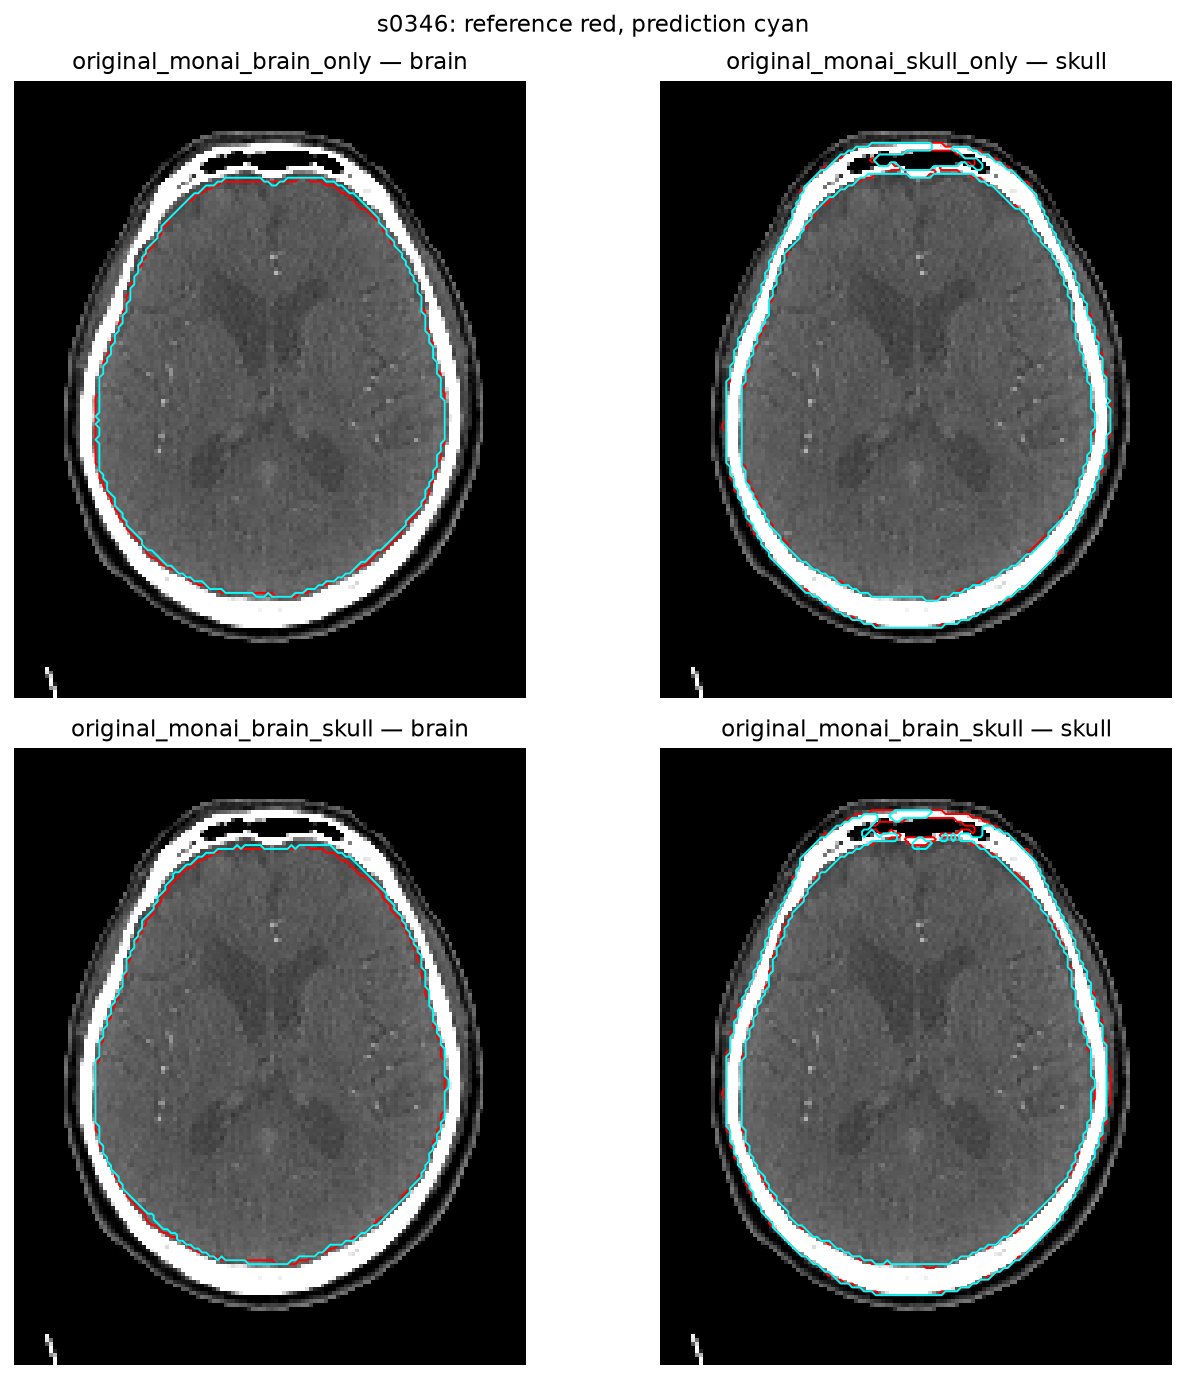

In [5]:
example = next(item for item in val_records if item["case_id"] == "s0346")
image = np.load(example["original_image_path"], mmap_mode="r")[0]
labels = np.load(example["label_path"], mmap_mode="r")
center_z = int(np.rint(np.argwhere(labels == 1)[:, 2].mean()))
panels = [
    ("original_monai_brain_only", "brain"),
    ("original_monai_skull_only", "skull"),
    ("original_monai_brain_skull", "brain"),
    ("original_monai_brain_skull", "skull"),
]
fig, axes = plt.subplots(2, 2, figsize=(10, 10), dpi=140)
for axis, (model_name, organ) in zip(axes.flat, panels):
    path = Path(reports[model_name]["best_checkpoint"])
    checkpoint = torch.load(path, map_location="cpu", weights_only=True)
    assert checkpoint["contract_sha256"] == reports[model_name]["contract_sha256"]
    assert sha256_file(path) == reports[model_name]["best_checkpoint_sha256"]
    model = make_model(model_name).cuda()
    model.load_state_dict(checkpoint["model_state"])
    model.eval()
    prediction = predict_case(
        model, example, device=torch.device("cuda"), roi=ROI, image_key="original_image_path"
    )
    target_id = 2 if organ == "skull" else 1
    prediction_id = 1 if ORIGINAL_TASKS[model_name] != "joint" else target_id
    axis.imshow(image[:, :, center_z].T, cmap="gray", vmin=0.45, vmax=0.65, origin="lower")
    axis.contour((labels[:, :, center_z] == target_id).T, levels=[0.5], colors="red", linewidths=1)
    axis.contour((prediction[:, :, center_z] == prediction_id).T, levels=[0.5], colors="cyan", linewidths=1)
    axis.set_title(f"{model_name} — {organ}")
    axis.axis("off")
    del model
fig.suptitle("s0346: reference red, prediction cyan")
fig.tight_layout()
fig.savefig(OUTPUT_ROOT / "validation_overlay_original_unet_s0346.png", bbox_inches="tight")
plt.show()

## 5. What can be compared with TotalSegmentator/nnU-Net?

TotalSegmentator's `total` CT task includes brain and skull and is based on nnU-Net. However, the
`brain.nii.gz` and `skull.nii.gz` files used above come from the **TotalSegmentator dataset** itself.
Running a released TotalSegmentator model against those masks is not an independent external benchmark:
the release model uses a larger, partly non-public training set, and overlap with these subjects must be
established before using its outputs as an external comparator. Its official guide also cautions that
reproducing its released weights from public data will not produce identical results.

A fair **MONAI vs nnU-Net architecture/pipeline** comparison requires training a fresh nnU-Net v2 on
exactly the same 98 train cases and evaluating on the same five validation cases with the same target
definitions. A fair **MONAI vs released TotalSegmentator product** comparison requires an independent,
manually annotated CT cohort not used by either system, with identical masks and metrics. Neither
nnU-Net baseline nor external cohort is silently claimed here.

Sources: [TotalSegmentator's official nnU-Net training guide](https://github.com/wasserth/TotalSegmentator/blob/master/resources/train_nnunet.md),
[official TotalSegmentator class map](https://github.com/wasserth/TotalSegmentator#class-map-for-task-total),
[nnU-Net v2](https://github.com/MIC-DKFZ/nnUNet).